# **Pump Market Analysis-Grundfos**

Online news analysis

In [9]:
pip install selenium

  Using cached sortedcontainers-2.4.0-py2.py3-none-any.whl.metadata (10 kB)
  Using cached outcome-1.3.0.post0-py2.py3-none-any.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 558.9 kB/s eta 0:00:17
   -- ------------------------------------- 0.5/9.5 MB 558.9 kB/s eta 0:00:17
   --- ------------------------------------ 0.8/9.5 MB 568.6 kB/s eta 0:00:16
   --- ------------------------------------ 0.8/9.5 MB 568.6 kB/s eta 0:00:16
   ---- ----------------------------------- 1.0/9.5 MB 636.8 kB/s eta 0:00:14
   ---- ----------------------------------- 1.0/9.5 MB 636.8 kB/s eta 0:00:14
   ---- ----------------------------------- 1.0/9.5 MB 636.8 kB/s eta 0:00:14
   ----- -------------------

In [ ]:
from selenium import webdriver
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.common.by import By
from selenium.webdriver.support import expected_conditions as EC
from bs4 import BeautifulSoup
import json


driver = webdriver.Chrome()

url = "https://www.gminsights.com/industry-analysis/water-pumps-market"
driver.get(url)


wait = WebDriverWait(driver, 20)
wait.until(
    EC.presence_of_element_located((By.TAG_NAME, "body"))
)


html = driver.page_source


driver.quit()


soup = BeautifulSoup(html, "html.parser")

results = {}


for h2 in soup.find_all("h2", id=True):

    section_id = h2["id"]
    heading = h2.get_text(strip=True)

    section_data = {
        "heading": heading,
        "paragraphs": [],
        "list_items": []
    }


    for elem in h2.find_next_siblings():

        if elem.name == "h2":
            break

   
        if elem.name == "p":
            text = elem.get_text(" ", strip=True)

            if text:
                section_data["paragraphs"].append(text)

        
        elif elem.name == "ul":

            for li in elem.find_all("li", recursive=False):

                text = li.get_text(" ", strip=True)

                if text:
                    section_data["list_items"].append(text)

    results[section_id] = section_data


for section_id, section in results.items():

    print("\n" + "=" * 100)
    print("SECTION ID:", section_id)
    print("HEADING:", section["heading"])

    if section["paragraphs"]:
        print("\nPARAGRAPHS:")
        for p in section["paragraphs"]:
            print("-", p)

    if section["list_items"]:
        print("\nLIST ITEMS:")
        for item in section["list_items"]:
            print("•", item)


with open("water_pumps_market.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nData saved to water_pumps_market.json")


SECTION ID: marketSize
HEADING: Water Pumps Market Size

PARAGRAPHS:
- According to a recent study by Global Market Insights Inc., the global water pumps market was estimated at USD 55.3 billion in 2024. The market is expected to grow from USD 58 billion in 2025 to USD 90.8 billion in 2034, at a CAGR of 5.1%.

LIST ITEMS:
• The market has grown 37% since 2019, driven by government-led infrastructure and sustainability initiatives across major economies.
• In India, the government has prioritized agricultural modernization and rural water access through programs like PM-KUSUM, which promotes solar-powered water pumps to reduce diesel dependency and enhance irrigation efficiency.
• Additionally, the expansion of sewage treatment plants and desalination facilities under urban development schemes such as the Smart Cities Mission has increased demand for municipal and industrial water pumps.
• In the U.S., the Bipartisan Infrastructure Law has allocated over USD 50 billion to the Environme

In [26]:
pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from selenium import webdriver
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.common.by import By
from selenium.webdriver.support import expected_conditions as EC
from bs4 import BeautifulSoup
import pandas as pd


driver = webdriver.Chrome()

url = "https://www.gminsights.com/industry-analysis/water-pumps-market"
driver.get(url)

wait = WebDriverWait(driver, 20)
wait.until(
    EC.presence_of_element_located((By.TAG_NAME, "body"))
)

html = driver.page_source
driver.quit()


soup = BeautifulSoup(html, "html.parser")

rows = []

for h2 in soup.find_all("h2", id=True):

    section_id = h2["id"]
    heading = h2.get_text(strip=True)

    for elem in h2.find_next_siblings():

        if elem.name == "h2":
            break

        if elem.name == "ul":

            for li in elem.find_all("li", recursive=False):

                list_item = li.get_text(" ", strip=True)

                rows.append({
                    "section_id": section_id,
                    "heading": heading,
                    "list_item": list_item
                })


df = pd.DataFrame(rows)

print(df.head())


df.to_excel("water_pumps_list_items2.xlsx", index=False)


df.to_csv("water_pumps_list_items2.csv", index=False)

print(f"Total rows: {len(df)}")

   section_id                  heading  \
0  marketSize  Water Pumps Market Size   
1  marketSize  Water Pumps Market Size   
2  marketSize  Water Pumps Market Size   
3  marketSize  Water Pumps Market Size   
4  marketSize  Water Pumps Market Size   

                                           list_item  
0  The market has grown 37% since 2019, driven by...  
1  In India, the government has prioritized agric...  
2  Additionally, the expansion of sewage treatmen...  
3  In the U.S., the Bipartisan Infrastructure Law...  
4  Similarly, China’s Ministry of Water Resources...  
Total rows: 117


In [1]:
import pandas as pd
import numpy as np

In [3]:
df.head()

,section_id,heading,list_item
0,marketSize,Water Pumps Market Size,"The market has grown 37% since 2019, driven by..."
1,marketSize,Water Pumps Market Size,"In India, the government has prioritized agric..."
2,marketSize,Water Pumps Market Size,"Additionally, the expansion of sewage treatmen..."
3,marketSize,Water Pumps Market Size,"In the U.S., the Bipartisan Infrastructure Law..."
4,marketSize,Water Pumps Market Size,"Similarly, China’s Ministry of Water Resources..."


In [4]:
df.shape

(117, 3)

Sentences with word Grundfos

In [5]:
df[df['list_item'].str.contains(r'\bGrundfos\b', case=False, na=False)]


,section_id,heading,list_item
7,marketTrends,Water Pumps Market Trends,"The integration of IoT, AI, and cloud-based an..."
38,marketShare,Water Pumps Market Share,The top 5 companies in the water pumps industr...
39,marketShare,Water Pumps Market Share,Grundfos has built its competitive edge throug...
47,marketCompanies,Water Pumps Market Companies,Grundfos


sentences with  %

In [6]:
df['list_item'][df['list_item'].str.contains('%', regex=False, na=False)]


0     The market has grown 37% since 2019, driven by...
4     Similarly, China’s Ministry of Water Resources...
6     Despite strong policy support, the deployment ...
18    Agriculture accounts for approximately 70% of ...
26    Additionally, the U.S. agricultural sector con...
30    The strategy aims to improve water efficiency ...
38    The top 5 companies in the water pumps industr...
Name: list_item, dtype: object

In [25]:
pip install nltk


   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ------------- -------------------------- 0.5/1.6 MB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 1.6/1.6 MB 4.3 MB/s  0:00:00

   ---------------------------------------- 0/2 [regex]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------

In [131]:
a=df[df['list_item'].str.contains(r'\bGrundfos\b', case=False, na=False)]

In [8]:
a

,section_id,heading,list_item
7,marketTrends,Water Pumps Market Trends,"The integration of IoT, AI, and cloud-based an..."
38,marketShare,Water Pumps Market Share,The top 5 companies in the water pumps industr...
39,marketShare,Water Pumps Market Share,Grundfos has built its competitive edge throug...
47,marketCompanies,Water Pumps Market Companies,Grundfos


In [132]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sent = SentimentIntensityAnalyzer()

a['list_item'].apply(sent.polarity_scores)


7     {'neg': 0.036, 'neu': 0.807, 'pos': 0.158, 'co...
38    {'neg': 0.0, 'neu': 0.846, 'pos': 0.154, 'comp...
39    {'neg': 0.021, 'neu': 0.777, 'pos': 0.202, 'co...
47    {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...
Name: list_item, dtype: object

In [133]:


def review_rating(string):
    scores = sent.polarity_scores(str(string))
    if scores['compound'] == 0:
        return 'Neutral'
    elif scores['compound'] > 0:
        return 'Positive'
    else:
        return 'Negative'

a['sentiment'] = a['list_item'].apply(review_rating)
df['sentiment'] = df['list_item'].apply(review_rating)
print(a)

         section_id                       heading  \
7      marketTrends     Water Pumps Market Trends   
38      marketShare      Water Pumps Market Share   
39      marketShare      Water Pumps Market Share   
47  marketCompanies  Water Pumps Market Companies   

                                            list_item sentiment  
7   The integration of IoT, AI, and cloud-based an...  Positive  
38  The top 5 companies in the water pumps industr...  Positive  
39  Grundfos has built its competitive edge throug...  Positive  
47                                           Grundfos   Neutral  


C:\Users\kunni\AppData\Local\Temp\ipykernel_9804\1572329240.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  a['sentiment'] = a['list_item'].apply(review_rating)


In [11]:

df['list_item'].apply(review_rating).value_counts()


list_item
Neutral     67
Positive    43
Negative     7
Name: count, dtype: int64

In [64]:
from spacy import displacy
df.head()

,section_id,heading,list_item,sentiment,cleaned
0,marketSize,Water Pumps Market Size,"The market has grown 37% since 2019, driven by...",Neutral,market grow drive government lead infrastructu...
1,marketSize,Water Pumps Market Size,"In India, the government has prioritized agric...",Positive,india government prioritize agricultural moder...
2,marketSize,Water Pumps Market Size,"Additionally, the expansion of sewage treatmen...",Positive,additionally expansion sewage treatment plant ...
3,marketSize,Water Pumps Market Size,"In the U.S., the Bipartisan Infrastructure Law...",Positive,u.s bipartisan infrastructure law allocate usd...
4,marketSize,Water Pumps Market Size,"Similarly, China’s Ministry of Water Resources...",Positive,similarly china ministry water resource report...


In [66]:
a.head()

,section_id,heading,list_item,sentiment
7,marketTrends,Water Pumps Market Trends,"The integration of IoT, AI, and cloud-based an...",Positive
38,marketShare,Water Pumps Market Share,The top 5 companies in the water pumps industr...,Positive
39,marketShare,Water Pumps Market Share,Grundfos has built its competitive edge throug...,Positive
47,marketCompanies,Water Pumps Market Companies,Grundfos,Neutral


In [67]:
a['sentiment'].head()

7     Positive
38    Positive
39    Positive
47     Neutral
Name: sentiment, dtype: object

In [68]:
for text in a['list_item']:
    doc = nlp(str(text))

    for sent in doc.sents:
        displacy.render(sent, style='ent', jupyter=True)



c:\Users\kunni\anaconda3\envs\nlp_new\Lib\site-packages\spacy\displacy\__init__.py:215: UserWarning: [W006] No entities to visualize found in Doc object. If this is surprising to you, make sure the Doc was processed using a model that supports named entity recognition, and check the `doc.ents` property manually if necessary.
  warnings.warn(Warnings.W006)


In [130]:
df.head()

,section_id,heading,list_item
0,marketSize,Water Pumps Market Size,"The market has grown 37% since 2019, driven by..."
1,marketSize,Water Pumps Market Size,"In India, the government has prioritized agric..."
2,marketSize,Water Pumps Market Size,"Additionally, the expansion of sewage treatmen..."
3,marketSize,Water Pumps Market Size,"In the U.S., the Bipartisan Infrastructure Law..."
4,marketSize,Water Pumps Market Size,"Similarly, China’s Ministry of Water Resources..."


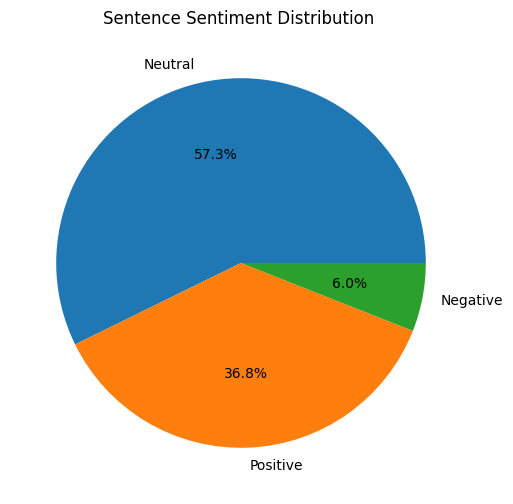

In [135]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6))
plt.pie(df['sentiment'].value_counts(),
        labels=df['sentiment'].value_counts().index,
        autopct='%1.1f%%')
plt.title('Sentence Sentiment Distribution ')
plt.show()

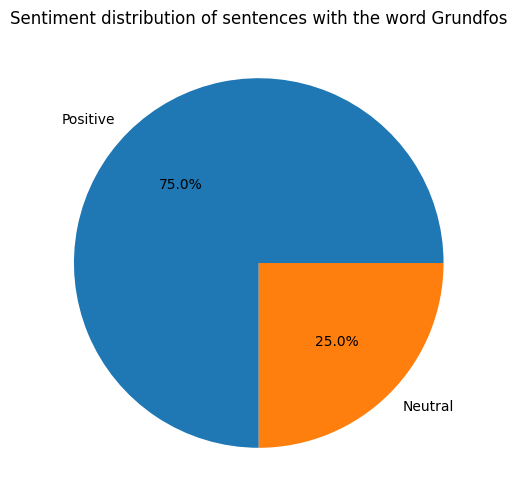

In [14]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6))
plt.pie(a['sentiment'].value_counts(),
        labels=a['sentiment'].value_counts().index,
        autopct='%1.1f%%')
plt.title('Sentiment distribution of sentences with the word Grundfos')
plt.show()

The majority of the sentences in which the word "Grundfos" appears are positive

**Topic Modelling**

In [39]:
from sklearn.feature_extraction.text import CountVectorizer

In [40]:
cv = CountVectorizer(max_df=0.95, min_df=2, stop_words='english')

In [73]:
dtm = cv.fit_transform(df['cleaned'])

In [74]:
dtm

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 1585 stored elements and shape (117, 736)>

In [75]:
from sklearn.decomposition import LatentDirichletAllocation

In [76]:
LDA = LatentDirichletAllocation(n_components=3,random_state=42)

In [77]:
LDA.fit(dtm)

,n_components,3
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'batch'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,10
,batch_size,128
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


In [78]:
import random
for i in range(10):
    random_word_id = random.randint(0,297)
    print(cv.get_feature_names_out()[random_word_id])

access
drink
expenditure
burdensome
diesel
america
catalyze
document
france
functionality


In [79]:
len(LDA.components_)

3

In [ ]:


feature_names = cv.get_feature_names_out()
print("Top 5 words per Topic")

for topic_num, topic in enumerate(LDA.components_):
    
    print(f"\nTOPIC {topic_num}")

    top_word_indices = topic.argsort()[-5:][::-1]

    

    for index in top_word_indices:
        print(feature_names[index])

Top 5 words per Topic

TOPIC 0
water
irrigation
pump
system
ksb

TOPIC 1
water
pump
usd
solar
system

TOPIC 2
pump
water
wastewater
municipal
infrastructure


In [107]:
pip install spacy

Note: you may need to restart the kernel to use updated packages.


In [109]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     --- ------------------------------------ 1.0/12.8 MB 2.2 MB/s eta 0:00:06
     ---- ----------------------------------- 1.6/12.8 MB 2.4 MB/s eta 0:00:05
     ------ --------------------------------- 2.1/12.8 MB 2.6 MB/s eta 0:00:05
     ------- -------------------------------- 2.4/12.8 MB 2.3 MB/s eta 0:00:05
     --------- ------------------------------ 3.1/12.8 MB 2.4 MB/s eta 0:00:05
     ---------- ----------------------------- 3.4/12.8 MB 2.4 MB/s eta 0:00:04
     ---------- ----------------------------- 3.4/12.8 MB 2.4 MB/s eta 0:00:04
     ---------- ----------------------------- 3.4/12.8 MB 2.4 MB/s eta 0:00:04
     ---------- ----------------------------- 3.4/12.8 MB 2.4 MB/s eta 0:00:04
     ---------- ----------------------------- 3.4/12.8 MB 2.4 MB/s eta 0:

In [82]:
import spacy
nlp = spacy.load("en_core_web_sm")

def spacy_preprocess(text):
    doc = nlp(text.lower())
    tokens = [token.lemma_ for token in doc 
              if not token.is_stop and 
              not token.is_punct and 
              not token.like_num and 
              len(token) > 2]
    return ' '.join(tokens)

df['cleaned'] = df['list_item'].apply(spacy_preprocess)

In [92]:
lda2 = LatentDirichletAllocation(n_components=3, random_state=42)


cv = CountVectorizer()
X = cv.fit_transform(df['cleaned'])
lda2.fit(X)

,n_components,3
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'batch'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,10
,batch_size,128
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


In [ ]:

top_word_indices = single_topic.argsort()[-5:]
for index in top_word_indices:
    print(cv.get_feature_names_out()[index])

announce
ambition
engine
customize
grow


In [97]:
for index,topic in enumerate(lda2.components_):
    print(f'THE TOP 5 WORDS FOR TOPIC #{index}')
    print([cv.get_feature_names_out()[i] for i in topic.argsort()[-5:]])
    print('\n')

THE TOP 5 WORDS FOR TOPIC #0
['ksb', 'system', 'pump', 'irrigation', 'water']


THE TOP 5 WORDS FOR TOPIC #1
['system', 'solar', 'usd', 'pump', 'water']


THE TOP 5 WORDS FOR TOPIC #2
['infrastructure', 'municipal', 'wastewater', 'water', 'pump']




In [69]:
from sklearn.decomposition import NMF
nmf_model = NMF(n_components=3,random_state=42)
nmf_model.fit(dtm)

,n_components,3
,init,None
,solver,'cd'
,beta_loss,'frobenius'
,tol,0.0001
,max_iter,200
,random_state,42
,alpha_W,0.0
,alpha_H,'same'
,l1_ratio,0.0
,verbose,0


In [70]:
topic_results = nmf_model.transform(dtm)

In [71]:
topic_results.shape

(117, 3)

In [72]:
df['Topic'] = topic_results.argmax(axis=1)
df.head()

,section_id,heading,list_item,sentiment,cleaned,Topic
0,marketSize,Water Pumps Market Size,"The market has grown 37% since 2019, driven by...",Neutral,market grow drive government lead infrastructu...,1
1,marketSize,Water Pumps Market Size,"In India, the government has prioritized agric...",Positive,india government prioritize agricultural moder...,0
2,marketSize,Water Pumps Market Size,"Additionally, the expansion of sewage treatmen...",Positive,additionally expansion sewage treatment plant ...,2
3,marketSize,Water Pumps Market Size,"In the U.S., the Bipartisan Infrastructure Law...",Positive,u.s bipartisan infrastructure law allocate usd...,0
4,marketSize,Water Pumps Market Size,"Similarly, China’s Ministry of Water Resources...",Positive,similarly china ministry water resource report...,0


In [87]:
mytopic_dict={0:'entity',1:'energy',2:'governance'}

In [100]:
df = df.drop('topic_label', axis=1)

In [101]:
df['list_item_topic']=df['Topic'].map(mytopic_dict)
df.head()

,section_id,heading,list_item,sentiment,cleaned,Topic,list_item_topic
0,marketSize,Water Pumps Market Size,"The market has grown 37% since 2019, driven by...",Neutral,market grow drive government lead infrastructu...,1,energy
1,marketSize,Water Pumps Market Size,"In India, the government has prioritized agric...",Positive,india government prioritize agricultural moder...,0,entity
2,marketSize,Water Pumps Market Size,"Additionally, the expansion of sewage treatmen...",Positive,additionally expansion sewage treatment plant ...,2,governance
3,marketSize,Water Pumps Market Size,"In the U.S., the Bipartisan Infrastructure Law...",Positive,u.s bipartisan infrastructure law allocate usd...,0,entity
4,marketSize,Water Pumps Market Size,"Similarly, China’s Ministry of Water Resources...",Positive,similarly china ministry water resource report...,0,entity


Indian Pump Market

In [ ]:
from selenium import webdriver
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.common.by import By
from selenium.webdriver.support import expected_conditions as EC
from bs4 import BeautifulSoup
import pandas as pd


driver = webdriver.Chrome()

url = "https://www.indianpumps.org/article_details/6"
driver.get(url)

wait = WebDriverWait(driver, 20)
wait.until(
    EC.presence_of_element_located((By.TAG_NAME, "body"))
)

html = driver.page_source
driver.quit()


soup = BeautifulSoup(html, "html.parser")

rows = []

for h2 in soup.find_all("h2", id=True):

    section_id = h2["id"]
    heading = h2.get_text(strip=True)

    for elem in h2.find_next_siblings():

        if elem.name == "h2":
            break

        if elem.name == "ul":

            for li in elem.find_all("li", recursive=False):

                list_item = li.get_text(" ", strip=True)

                rows.append({
                    "section_id": section_id,
                    "heading": heading,
                    "list_item": list_item
                })


df = pd.DataFrame(rows)

print(df.head())


In [103]:
pip install lxml

   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.5/4.0 MB 1.7 MB/s eta 0:00:03
   ------- -------------------------------- 0.8/4.0 MB 1.2 MB/s eta 0:00:03
   ------- -------------------------------- 0.8/4.0 MB 1.2 MB/s eta 0:00:03
   ---------- ----------------------------- 1.0/4.0 MB 1.0 MB/s eta 0:00:03
   ------------- -------------------------- 1.3/4.0 MB 882.6 kB/s eta 0:00:04
   ------------- -------------------------- 1.3/4.0 MB 882.6 kB/s eta 0:00:04
   ------------- -------------------------- 1.3/4.0 MB 882.6 kB/s eta 0:00:04
   --------------- ------------------------ 1.6/4.0 MB 769.7 kB/s eta 0:00:04
   ------------------ --------------------- 1.8/4.0 MB 805.4 kB/s eta 0:00:03
   -------------------- ------------------- 2.1/4.0 MB 857.1 kB/s eta 0:00:03
   ------------------

In [105]:
import pandas as pd

url = "https://www.indianpumps.org/article_details/6"

tables = pd.read_html(url)

for i, table in enumerate(tables):
    print(f"\nTable {i}")
    print(table.head())


Table 0
                               0             1
0                     Industries  Market Share
1                    Agriculture           27%
2              Building Services           19%
3  Water & Wastewater Management           17%
4               Power Generation           12%


In [109]:
pip install html5lib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
df = tables[0]

df.columns = df.iloc[0]
df = df.iloc[2:].reset_index(drop=True)

print(df.head())

0                     Industries Market Share
0              Building Services          19%
1  Water & Wastewater Management          17%
2               Power Generation          12%
3                      Oil & Gas           8%
4                 Metal & Mining           4%


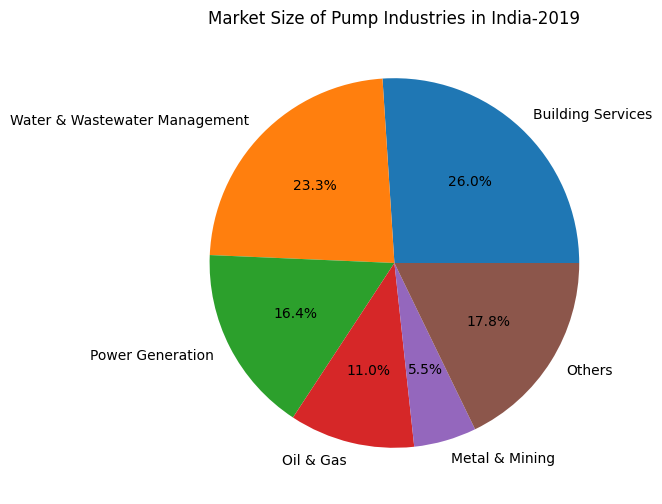

In [126]:
import matplotlib.pyplot as plt


labels = df['Industries']
sizes = df['Market Share']

plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%')
plt.title('Market Size of Pump Industries in India-2019')
plt.show()

# Pump Maintainenance Analysis

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style('whitegrid')

In [7]:
df2.head()

,Unnamed: 0,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
0,0,2018-04-01 00:00:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
1,1,2018-04-01 00:01:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
2,2,2018-04-01 00:02:00,2.444734,47.35243,53.2118,46.397570,638.8889,73.54598,13.32465,16.03733,...,41.66666,39.351852,65.39352,51.21528,38.194443,155.9606,67.12963,241.3194,203.7037,NORMAL
3,3,2018-04-01 00:03:00,2.460474,47.09201,53.1684,46.397568,628.1250,76.98898,13.31742,16.24711,...,40.88541,39.062500,64.81481,51.21528,38.194440,155.9606,66.84028,240.4514,203.1250,NORMAL
4,4,2018-04-01 00:04:00,2.445718,47.13541,53.2118,46.397568,636.4583,76.58897,13.35359,16.21094,...,41.40625,38.773150,65.10416,51.79398,38.773150,158.2755,66.55093,242.1875,201.3889,NORMAL


In [8]:
df2.shape

(220320, 55)

In [9]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220320 entries, 0 to 220319
Data columns (total 55 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Unnamed: 0      220320 non-null  int64  
 1   timestamp       220320 non-null  object 
 2   sensor_00       210112 non-null  float64
 3   sensor_01       219951 non-null  float64
 4   sensor_02       220301 non-null  float64
 5   sensor_03       220301 non-null  float64
 6   sensor_04       220301 non-null  float64
 7   sensor_05       220301 non-null  float64
 8   sensor_06       215522 non-null  float64
 9   sensor_07       214869 non-null  float64
 10  sensor_08       215213 non-null  float64
 11  sensor_09       215725 non-null  float64
 12  sensor_10       220301 non-null  float64
 13  sensor_11       220301 non-null  float64
 14  sensor_12       220301 non-null  float64
 15  sensor_13       220301 non-null  float64
 16  sensor_14       220299 non-null  float64
 17  sensor_15 

In [10]:

df2.timestamp=pd.to_datetime(df2.timestamp)

df2.machine_status=df2.machine_status.astype('category')

In [11]:
df2.set_index('timestamp',inplace=True)

In [12]:
df2.index.is_unique

True

In [13]:
df2.isnull().sum()

Unnamed: 0             0
sensor_00          10208
sensor_01            369
sensor_02             19
sensor_03             19
sensor_04             19
sensor_05             19
sensor_06           4798
sensor_07           5451
sensor_08           5107
sensor_09           4595
sensor_10             19
sensor_11             19
sensor_12             19
sensor_13             19
sensor_14             21
sensor_15         220320
sensor_16             31
sensor_17             46
sensor_18             46
sensor_19             16
sensor_20             16
sensor_21             16
sensor_22             41
sensor_23             16
sensor_24             16
sensor_25             36
sensor_26             20
sensor_27             16
sensor_28             16
sensor_29             72
sensor_30            261
sensor_31             16
sensor_32             68
sensor_33             16
sensor_34             16
sensor_35             16
sensor_36             16
sensor_37             16
sensor_38             27


In [14]:
df2.drop(columns=['sensor_15'],inplace=True)

df2.drop(columns=['Unnamed: 0'],inplace=True)

In [15]:
df2.index.max() - df2.index.min()

Timedelta('152 days 23:59:00')

machine_status
NORMAL        205836
RECOVERING     14477
BROKEN             7
Name: count, dtype: int64


C:\Users\kunni\AppData\Local\Temp\ipykernel_3628\183637015.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='machine_status',data=df2,palette='Blues_d');


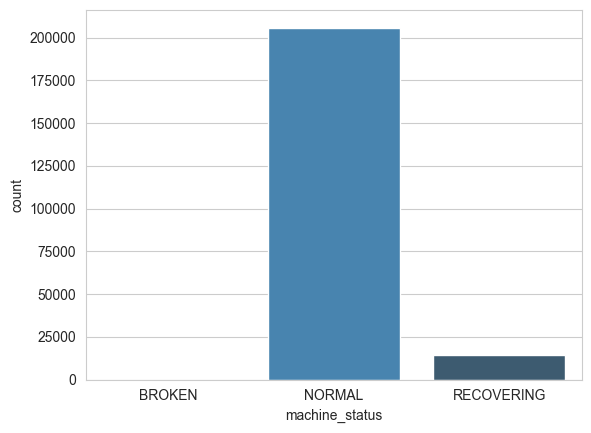

In [16]:
print(df2.machine_status.value_counts())
sns.countplot(x='machine_status',data=df2,palette='Blues_d');

In [17]:
df_final=df2[['sensor_00', 'sensor_01', 'sensor_02', 'sensor_03', 'sensor_04','sensor_05','machine_status']]

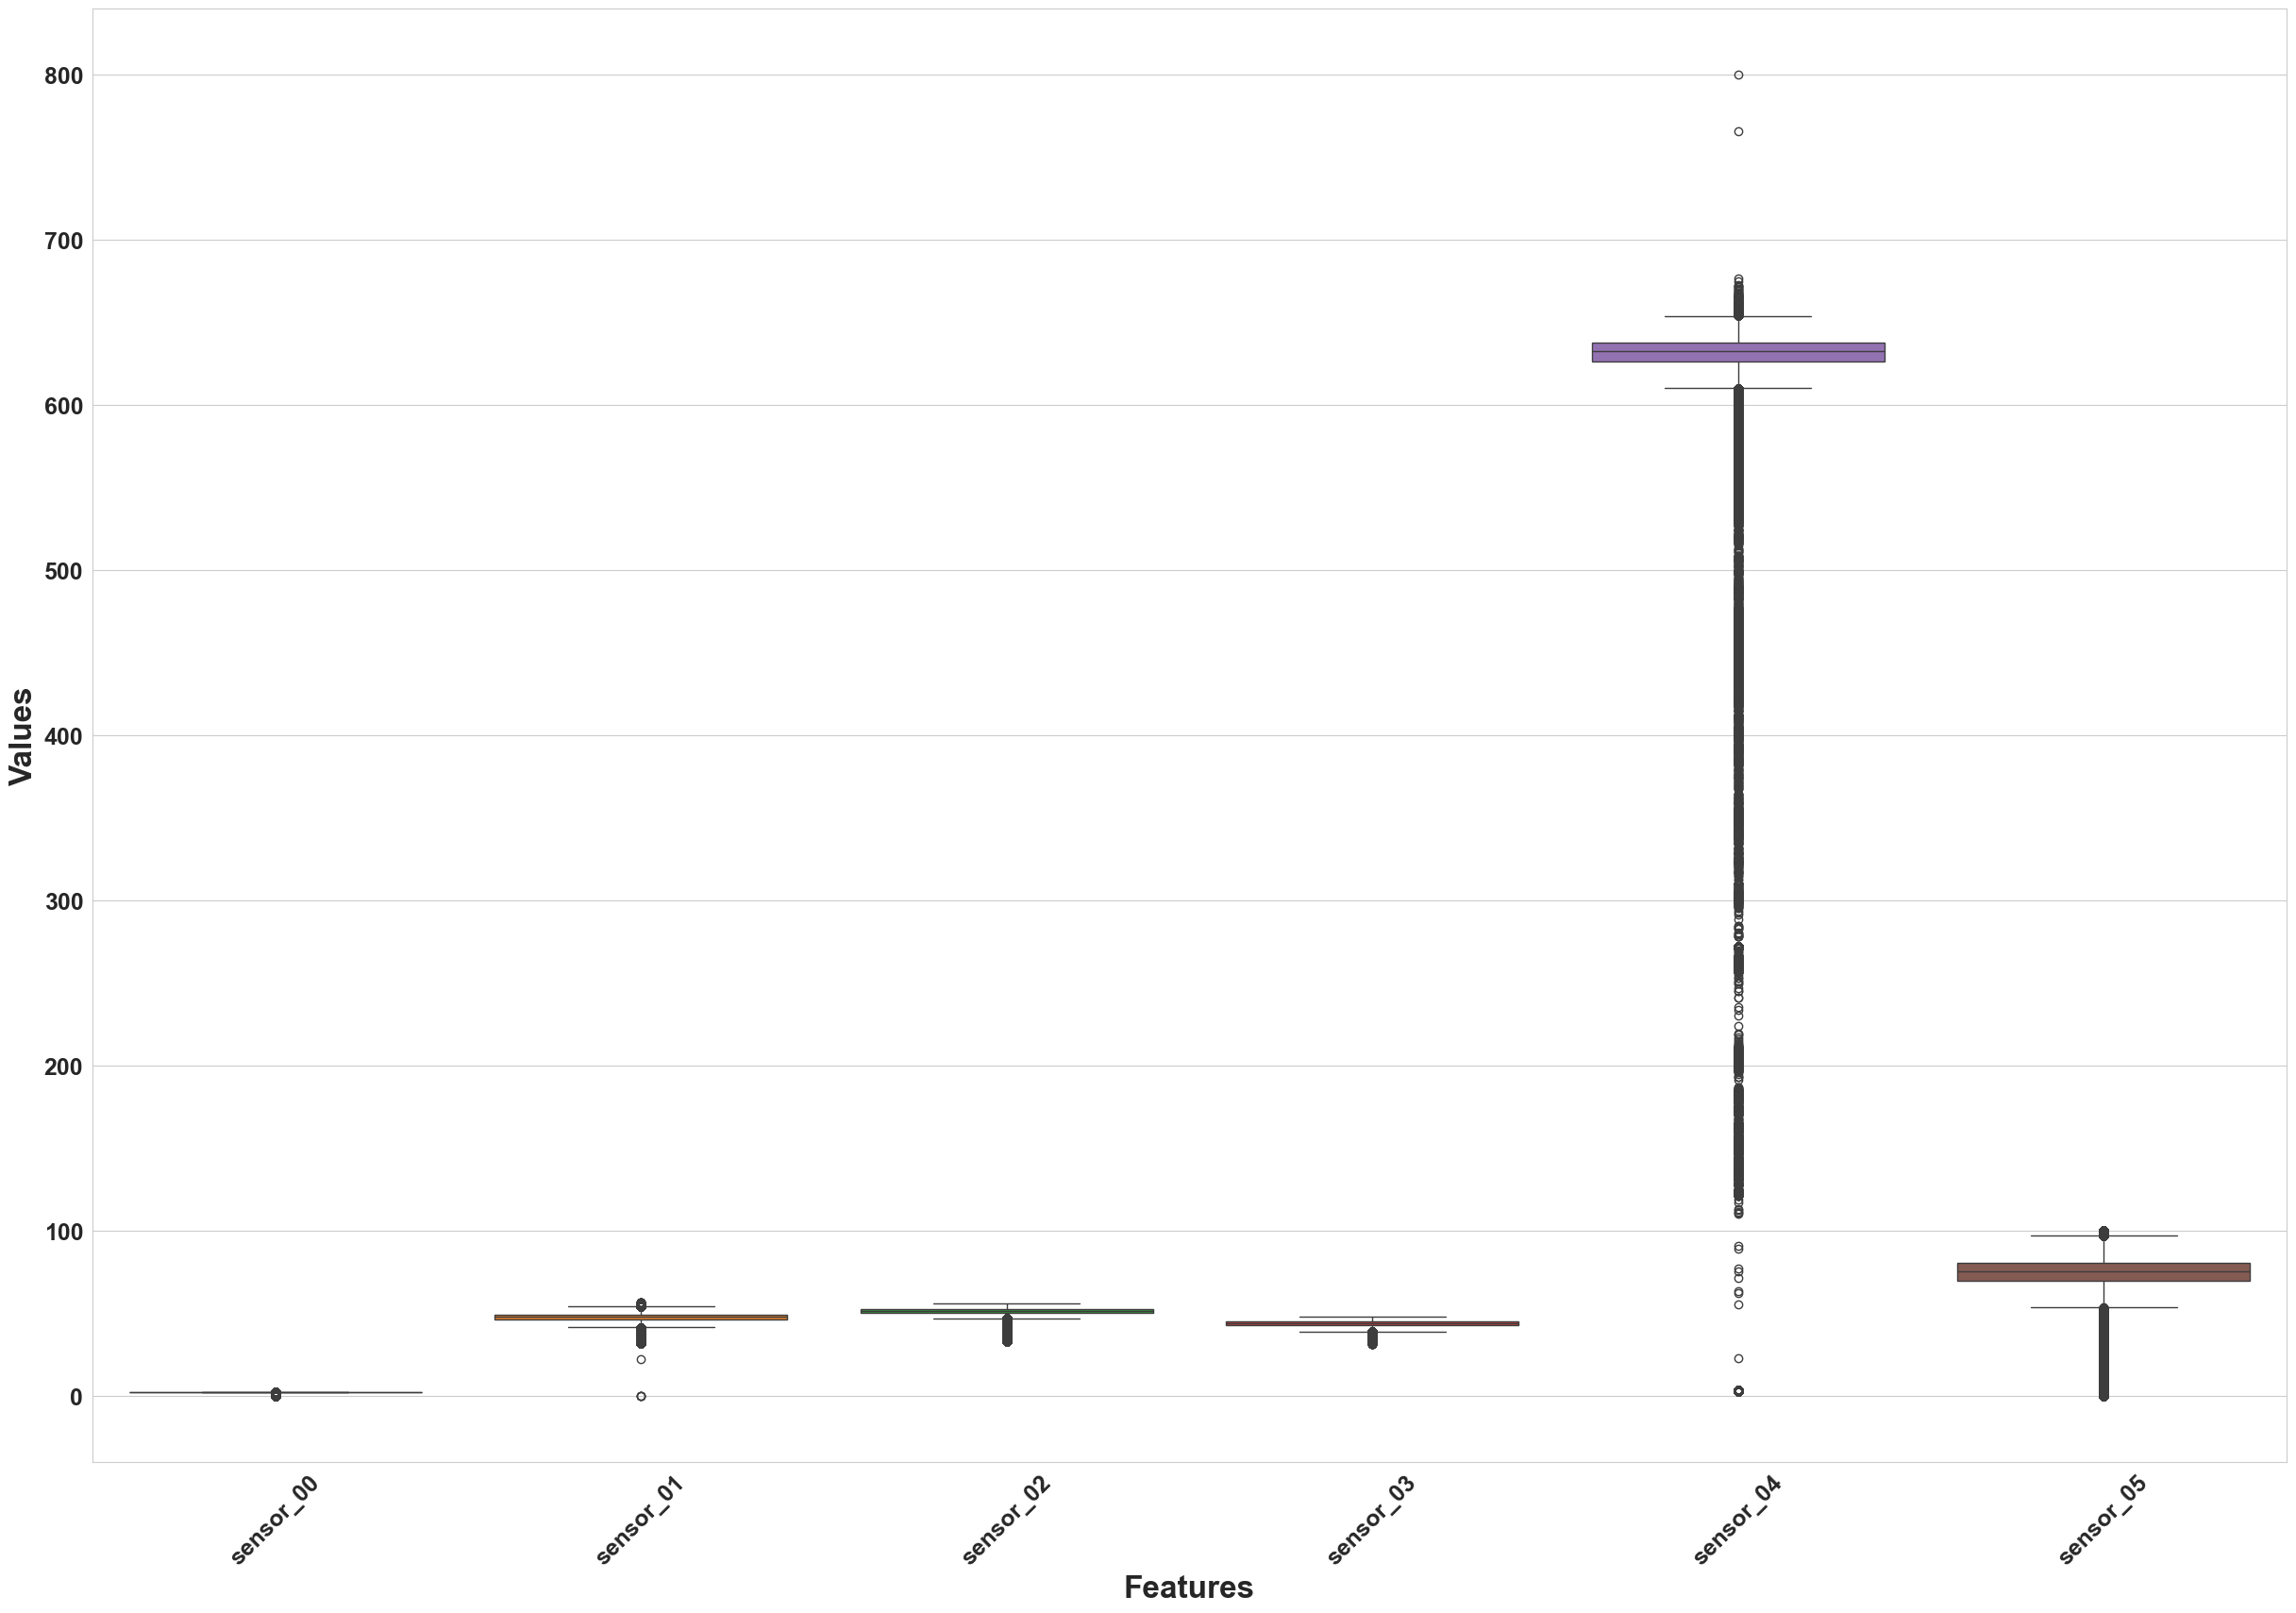

In [18]:

plt.figure(figsize=(30,20))
sns.boxplot(data=df_final)

plt.xlabel('Features', fontsize=24, fontweight='bold')
plt.ylabel('Values', fontsize=24, fontweight='bold')

plt.xticks(fontsize=18, fontweight='bold', rotation=45)
plt.yticks(fontsize=18, fontweight='bold')

plt.show()

Sensor 4 has high values

In [19]:
df_final.describe()

,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05
count,210112.000000,219951.000000,220301.000000,220301.000000,220301.000000,220301.000000
mean,2.372221,47.591611,50.867392,43.752481,590.673936,73.396414
std,0.412227,3.296666,3.666820,2.418887,144.023912,17.298247
min,0.000000,0.000000,33.159720,31.640620,2.798032,0.000000
25%,2.438831,46.310760,50.390620,42.838539,626.620400,69.976260
50%,2.456539,48.133678,51.649300,44.227428,632.638916,75.576790
75%,2.499826,49.479160,52.777770,45.312500,637.615723,80.912150
max,2.549016,56.727430,56.032990,48.220490,800.000000,99.999880


<Axes: >

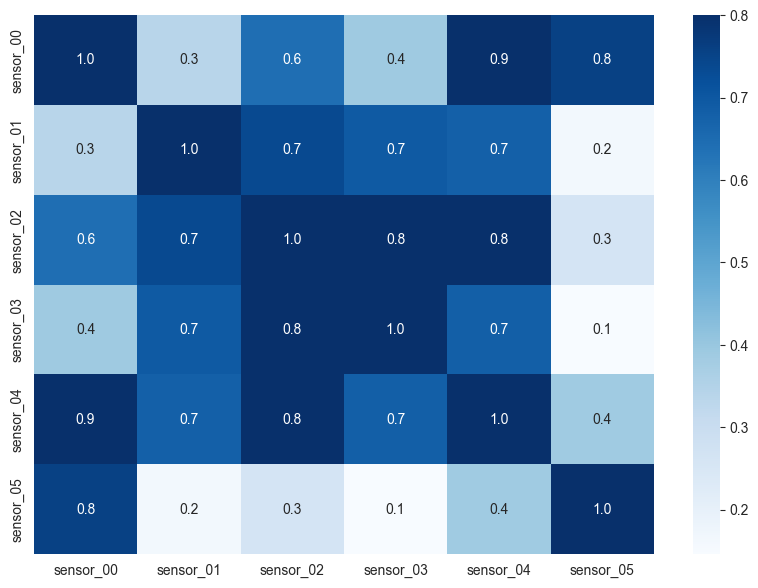

In [20]:
plt.figure(figsize=(10,7))
correlation=df_final[['sensor_00','sensor_01','sensor_02','sensor_03','sensor_04','sensor_05']].corr()
sns.heatmap(correlation,cbar=True,fmt='.1f',vmax=0.8,annot=True,cmap='Blues')

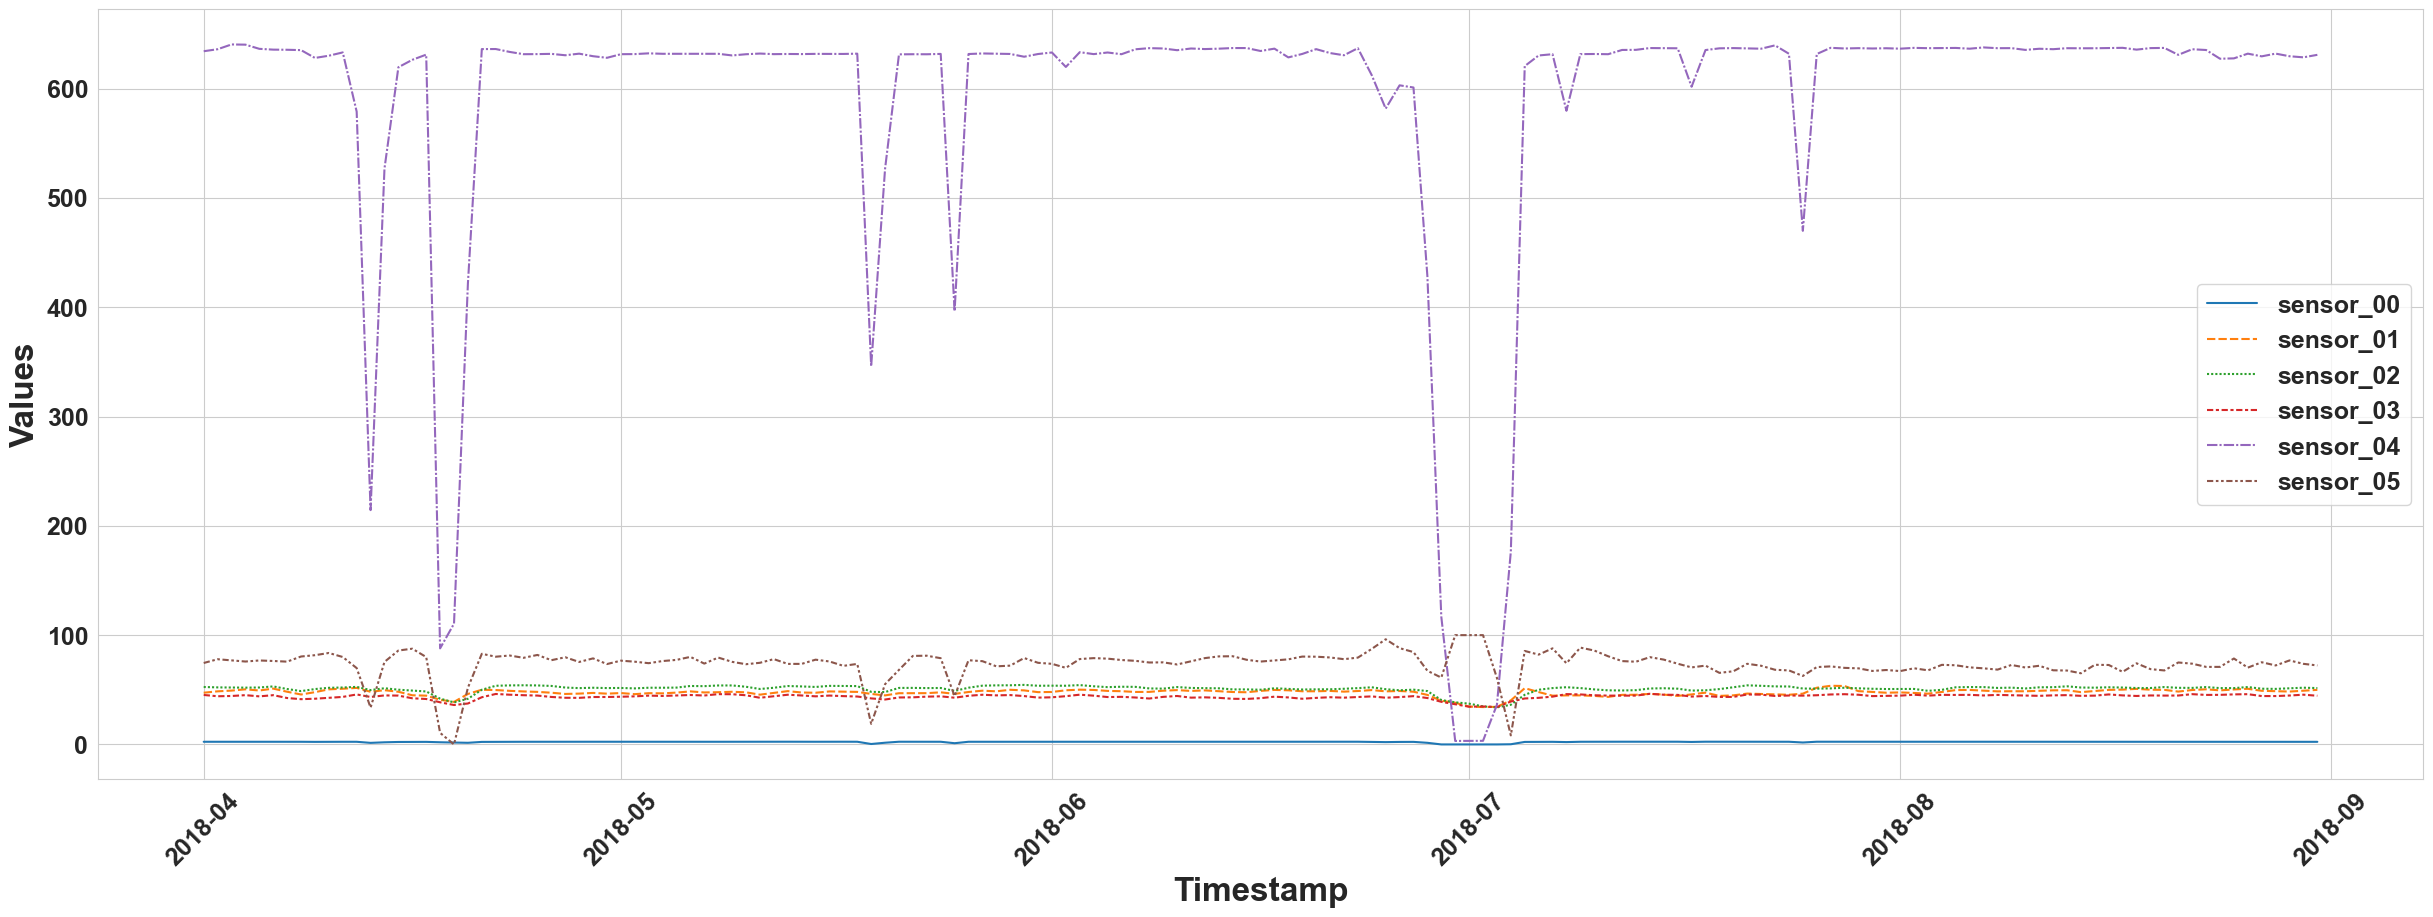

In [21]:
plt.figure(figsize=(30,10))
sns.lineplot(data=df_final[['sensor_00','sensor_01','sensor_02','sensor_03','sensor_04','sensor_05']].resample('D').mean())
plt.xlabel('Timestamp', fontsize=24, fontweight='bold')
plt.ylabel('Values', fontsize=24, fontweight='bold')

plt.xticks(fontsize=18, fontweight='bold', rotation=45)
plt.yticks(fontsize=18, fontweight='bold')
plt.legend(fontsize=18, prop={'weight': 'bold', 'size': 18})
plt.show()

Sensor 4 exhibits significant variation in its values during a certain time period

C:\Users\kunni\AppData\Local\Temp\ipykernel_3628\3965893668.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=18, prop={'weight': 'bold', 'size': 18})


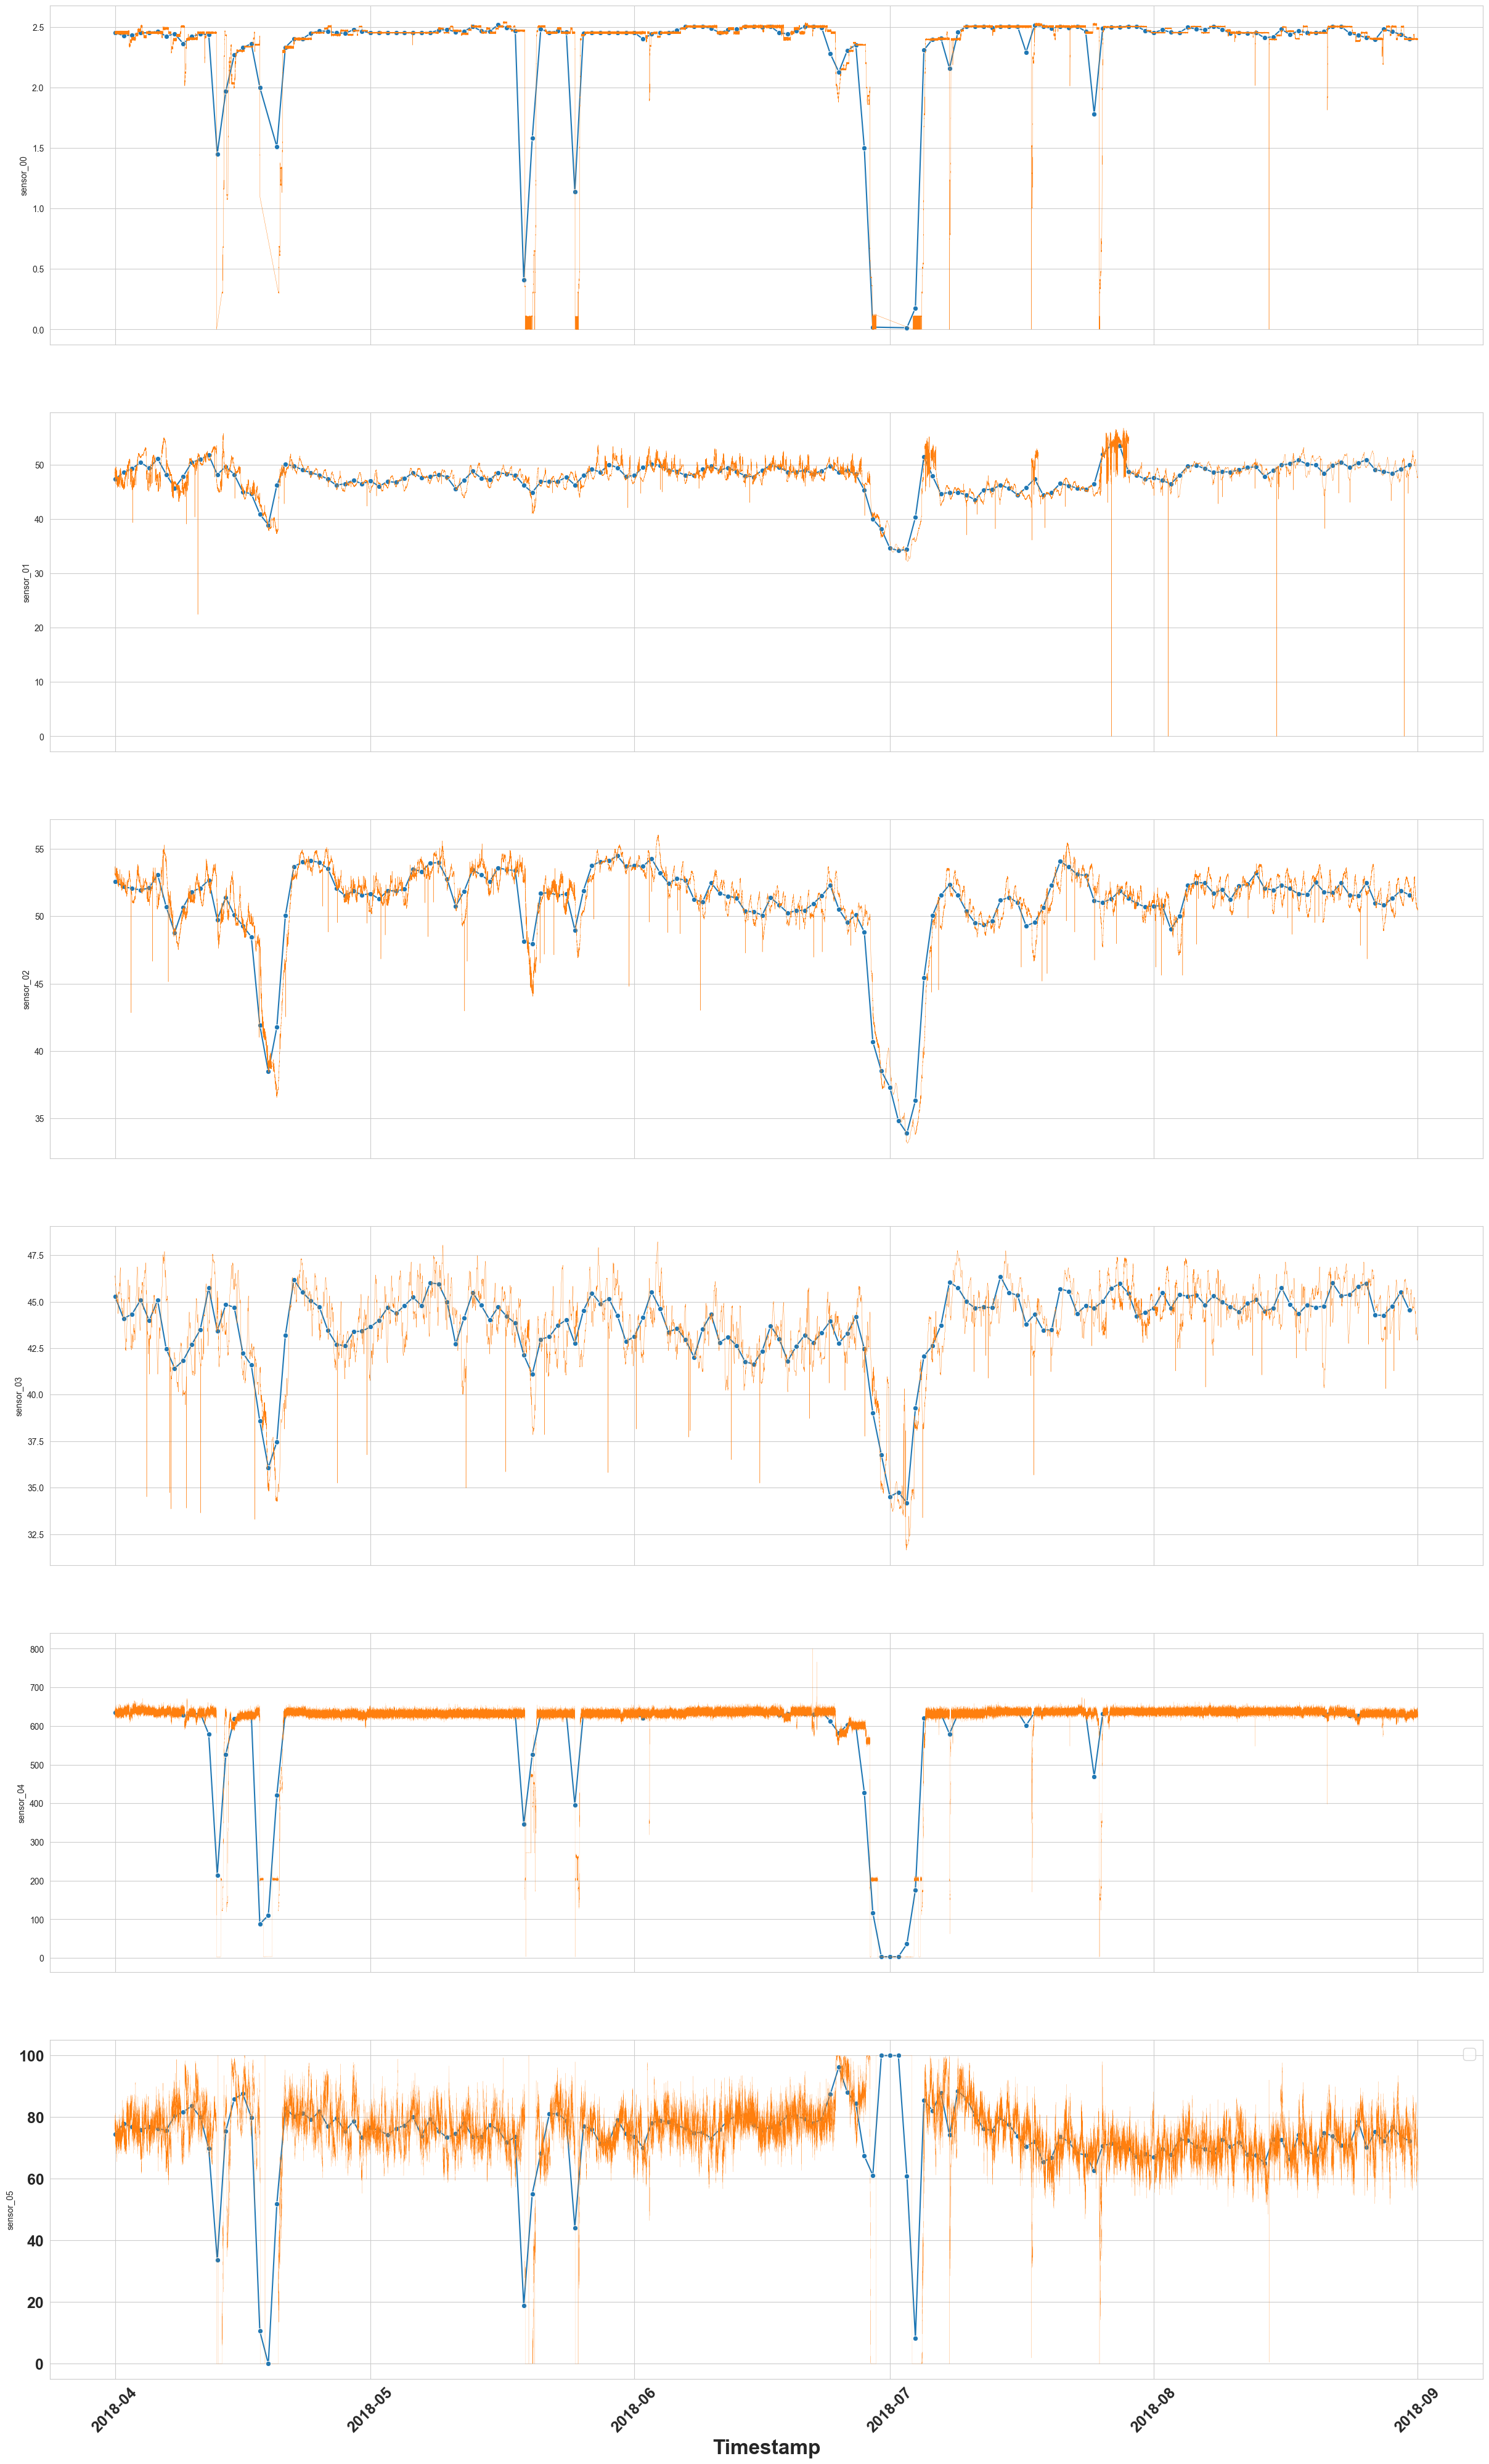

In [22]:
fig,ax=plt.subplots(ncols=1,nrows=6,sharex=True,figsize=(30,50))
sns.lineplot(data=df_final.sensor_00.resample('D').mean(),marker='o',ax=ax[0])
sns.lineplot(x=df_final.index,y='sensor_00',data=df_final,linewidth=0.3,ax=ax[0])
sns.lineplot(data=df_final.sensor_01.resample('D').mean(),marker='o',ax=ax[1])
sns.lineplot(x=df_final.index,y='sensor_01',data=df_final,linewidth=0.3,ax=ax[1])
sns.lineplot(data=df_final.sensor_02.resample('D').mean(),marker='o',ax=ax[2])
sns.lineplot(x=df_final.index,y='sensor_02',data=df_final,linewidth=0.3,ax=ax[2])
sns.lineplot(data=df_final.sensor_03.resample('D').mean(),marker='o',ax=ax[3])
sns.lineplot(x=df_final.index,y='sensor_03',data=df_final,linewidth=0.3,ax=ax[3])
sns.lineplot(data=df_final.sensor_04.resample('D').mean(),marker='o',ax=ax[4])
sns.lineplot(x=df_final.index,y='sensor_04',data=df_final,linewidth=0.1,ax=ax[4])
sns.lineplot(data=df_final.sensor_05.resample('D').mean(),marker='o',ax=ax[5])
sns.lineplot(x=df_final.index,y='sensor_05',data=df_final,linewidth=0.1,ax=ax[5])

plt.xlabel('Timestamp', fontsize=24, fontweight='bold')


plt.xticks(fontsize=18, fontweight='bold', rotation=45)
plt.yticks(fontsize=18, fontweight='bold')
plt.legend(fontsize=18, prop={'weight': 'bold', 'size': 18})
plt.show()


In [23]:
pwd

'c:\\UNNI\\Analytics\\data\\Analytics files\\Visual_studio'